<h1 style="background-color: gray;
           color: black;
           padding: 20px;
           text-align: center;">INFO</h1>

In this script, we run player `Dijkstra` in a maze, to visualize its behavior.

<h1 style="background-color: gray;
           color: black;
           padding: 20px;
           text-align: center;">IMPORTS</h1>

In [1]:
# External imports
import sys
import os
import pprint

# Add needed directories to the path
sys.path.append(os.path.join("..", "players"))

# PyRat imports
from pyrat import Game, GameMode
from CompetPlayer import CompetPlayer

<h1 style="background-color: gray;
           color: black;
           padding: 20px;
           text-align: center;">CONSTANTS</h1>

Let's configure the game with a dictionary.

In [2]:
# Customize the game elements
CONFIG = {"maze_width": 25,
          "maze_height": 20,
          "cell_percentage": 80,
          "wall_percentage": 60,
          "mud_percentage": 20.0,
          "mud_range": [4, 9],
          "nb_cheese": 41,
          "preprocessing_time": 3.0,
          "turn_time": 0.1,
          "random_seed": 42,
          "trace_length": 1000,
          "game_mode": GameMode.SEQUENTIAL}

<h1 style="background-color: gray;
           color: black;
           padding: 20px;
           text-align: center;">RUN THE GAME</h1>

We perform a single game with the configuration defined above.

In [3]:
# Instantiate a game with specified arguments
game = Game(**CONFIG)

# Instantiate a player and add it to the game
player = CompetPlayer()
game.add_player(player)

# Start the game and
stats = game.start()

27
[[23. 23. 23. 23. 23.  0.  0.  2.  2.  2.  2.  0.  0.  0.  0.  0.  0.  0.
   0.  0.  0.  0.  0.  0.  0.]
 [23. 23. 23.  0. 23. 23.  2.  2.  2.  0.  0.  0.  0.  0.  0.  0.  0.  0.
   0.  0.  0.  0.  0. 12. 12.]
 [23. 23.  8.  0. 23. 23.  2.  2.  2.  2.  2.  0.  0.  0.  0.  0.  0.  0.
   0.  0.  0.  0.  0.  3.  0.]
 [21.  0.  8.  0.  0.  0. 10. 10. 10.  2.  0. 25. 25. 25. 25.  0.  0.  0.
   0.  0.  0.  3.  3.  3.  3.]
 [21. 21.  0.  0.  0.  0.  0. 10. 10.  0.  0.  0.  0. 25. 25. 25. 25. 24.
  24.  3.  3.  3.  3.  3.  0.]
 [21. 21.  0.  0.  0. 10. 10. 10. 10.  0.  0.  0.  0. 25. 25. 25.  4. 24.
   4.  3.  3.  3.  0.  3.  0.]
 [21. 21. 21.  0.  0.  0. 10. 10. 10. 10.  0.  0.  6.  6.  6.  4.  4.  4.
   4.  7.  3.  3.  3.  3. 27.]
 [ 0.  0.  0.  0.  0.  0.  0. 10. 10. 10.  6.  6.  6.  6.  0.  0.  0.  4.
   7.  7.  3. 27. 27. 27. 27.]
 [ 0.  0.  0.  0.  0. 11. 11. 11.  0.  0.  6.  6.  6.  6.  0.  0.  0.  4.
   0.  0.  0. 27. 27. 27. 27.]
 [ 0.  0.  0.  0. 11. 11. 11. 11. 11.  0.  6.  6.  6

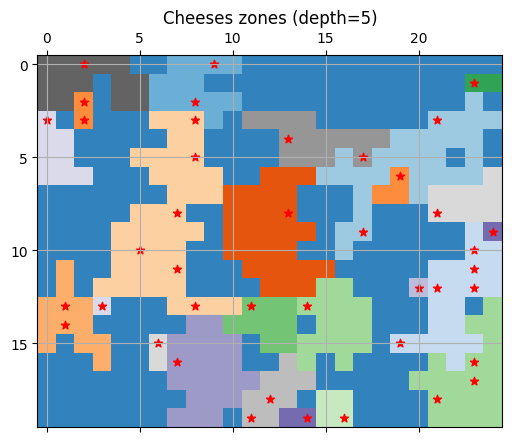

In [4]:
import numpy as np
import matplotlib.pyplot as plt

mat = np.zeros((CONFIG['maze_height'], CONFIG['maze_width']))
pos_cheese = np.array([game.maze.i_to_rc(cheese) for cheese in player.cheeses])

index = 2

for zone in player.zones:
    for cell in player.zones[zone]['cells']:
        row, column = game.maze.i_to_rc(cell)
        mat[row,column] = index
    index += 1

print(len(player.zones))

print(mat)

plt.matshow(mat, cmap='tab20c')
plt.scatter(pos_cheese[:,1], pos_cheese[:,0], marker = '*', color='r')
plt.title('Cheeses zones (depth=5)')
plt.grid()

We visualize results using a pretty printer.

In [5]:
# Show statistics
pprint.pprint(stats)

{'players': {'CompetPlayer': {'actions': {'east': 62,
                                          'error': 0,
                                          'miss': 0,
                                          'mud': 91,
                                          'north': 62,
                                          'nothing': 0,
                                          'south': 71,
                                          'wall': 0,
                                          'west': 60},
                              'preprocessing_duration': 0.0625,
                              'score': 41.0,
                              'turn_durations': [0.0,
                                                 0.0,
                                                 0.0,
                                                 0.0,
                                                 0.0,
                                                 0.0,
                                                 0.0,
                         